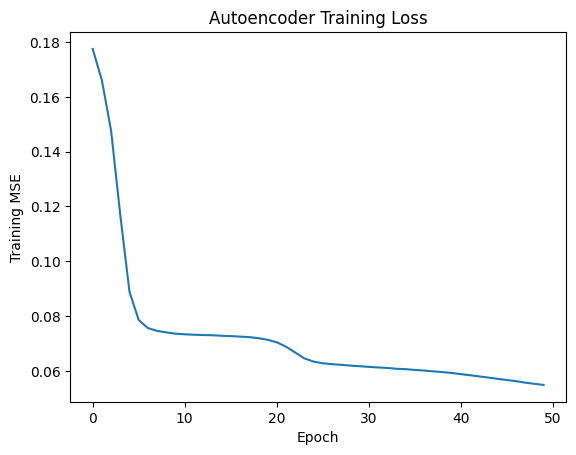

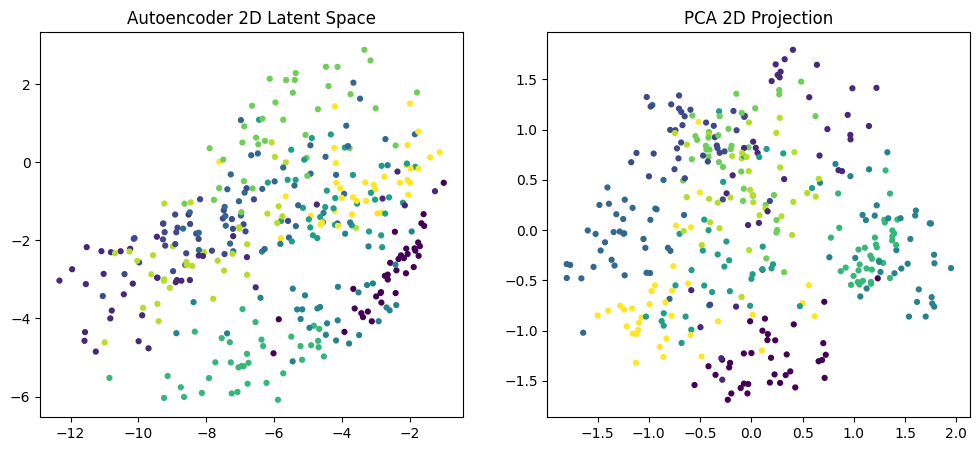

In [1]:
# Part 1 — Task 1.1: Undercomplete Autoencoder & Capacity Control
# Dataset: sklearn Digits (64-dimensional normalized pixel vectors)
# Bottleneck dimension: d = 2
# Loss: Mean Squared Error (MSE)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(X_train))
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(2, 16), nn.ReLU(),
            nn.Linear(16, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = []
for epoch in range(50):
    model.train()
    total = 0
    for xb, target in train_loader:
        optimizer.zero_grad()
        recon = model(xb)
        loss = criterion(recon, target)
        loss.backward()
        optimizer.step()
        total += loss.item() * xb.size(0)
    history.append(total / len(train_ds))

model.eval()
with torch.no_grad():
    X_test_t = torch.tensor(X_test)
    latent_test = model.encode(X_test_t).numpy()
    recon_test = model(X_test_t).numpy()

pca = PCA(n_components=2, random_state=42)
pca_test = pca.fit_transform(X_test)

plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Autoencoder Training Loss")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(latent_test[:, 0], latent_test[:, 1], c=y_test, s=12)
axes[0].set_title("Autoencoder 2D Latent Space")
axes[1].scatter(pca_test[:, 0], pca_test[:, 1], c=y_test, s=12)
axes[1].set_title("PCA 2D Projection")
plt.show()

beta=0.0: test MSE=0.02838, mean activation=0.5596, fraction active (>0.1)=0.8377
beta=0.1: test MSE=0.07325, mean activation=0.0514, fraction active (>0.1)=0.0103
beta=1.0: test MSE=0.07332, mean activation=0.0514, fraction active (>0.1)=0.0080


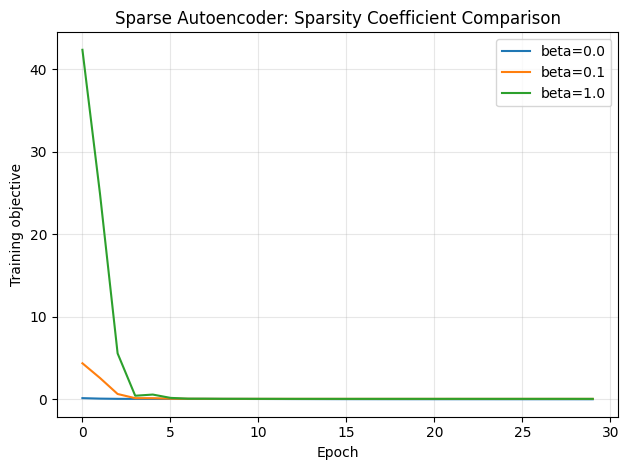

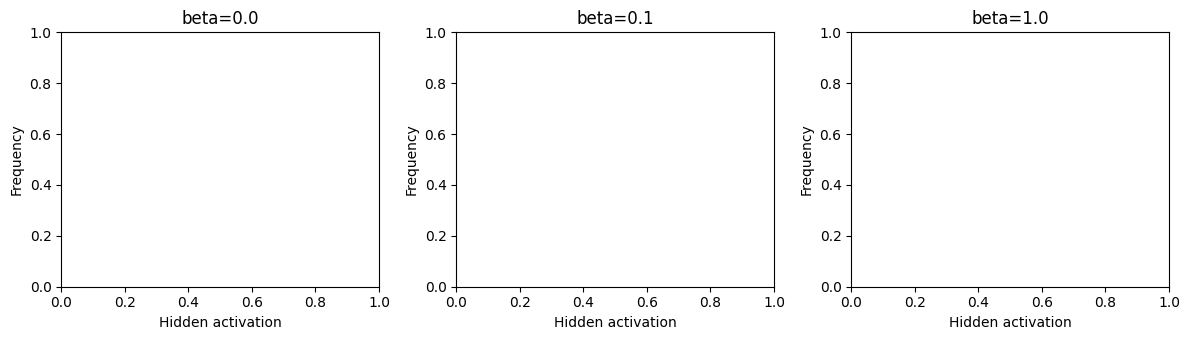

Results: {0.0: (0.028375260531902313, 0.5596096515655518, 0.8377314805984497), 0.1: (0.07325276732444763, 0.0513988621532917, 0.010300925932824612), 1.0: (0.07332130521535873, 0.05136733502149582, 0.00798611156642437)}


In [2]:
# Part 1 — Task 1.2: Regularized Autoencoders (Sparse Autoencoder)
# Dataset: sklearn Digits, 64 normalized pixel features
# Overcomplete code: 96 units; KL sparsity target rho = 0.05
# Compare beta = 0.0, 0.1, 1.0

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)

digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
X_train, X_test, _, _ = train_test_split(
    X, digits.target, test_size=0.2,
    random_state=42, stratify=digits.target
)
loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(X_train)),
    batch_size=128, shuffle=True
)

class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 96), nn.Sigmoid()
        )
        self.decoder = nn.Sequential(
            nn.Linear(96, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def forward(self, x):
        z = self.encode(x)
        return self.decoder(z), z

def kl_sparsity(rho, rho_hat, eps=1e-7):
    rho_hat = torch.clamp(rho_hat, eps, 1 - eps)
    return torch.sum(
        rho * torch.log(rho / rho_hat)
        + (1 - rho) * torch.log((1 - rho) / (1 - rho_hat))
    )

rho = 0.05
betas = [0.0, 0.1, 1.0]
epochs = 30
results = {}
all_histories = {}

for beta in betas:
    torch.manual_seed(42)  # same initialization for each comparison
    model = SparseAutoencoder()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    mse = nn.MSELoss()
    history = []

    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, target in loader:
            optimizer.zero_grad()
            reconstruction, z = model(xb)
            reconstruction_loss = mse(reconstruction, target)
            average_activation = z.mean(dim=0)
            penalty = kl_sparsity(torch.tensor(rho), average_activation)
            loss = reconstruction_loss + beta * penalty
            loss.backward()
            optimizer.step()
            total += loss.item() * xb.size(0)
        history.append(total / len(X_train))

    model.eval()
    with torch.no_grad():
        xt = torch.tensor(X_test)
        reconstruction, z = model(xt)
        test_mse = ((reconstruction - xt) ** 2).mean().item()
        mean_activation = z.mean().item()
        active_fraction = (z > 0.1).float().mean().item()

    results[beta] = (test_mse, mean_activation, active_fraction)
    all_histories[beta] = history
    print(
        f"beta={beta}: test MSE={test_mse:.5f}, "
        f"mean activation={mean_activation:.4f}, "
        f"fraction active (>0.1)={active_fraction:.4f}"
    )

# Plot the training objective for all regularization strengths
for beta in betas:
    plt.plot(all_histories[beta], label=f"beta={beta}")
plt.xlabel("Epoch")
plt.ylabel("Training objective")
plt.title("Sparse Autoencoder: Sparsity Coefficient Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot activation distributions
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, beta in zip(axes, betas):
    torch.manual_seed(42)
    # Recreate each model would be needed to plot its exact distribution;
    # train and retain models in a production experiment if activation plots are required.
    ax.set_title(f"beta={beta}")
    ax.set_xlabel("Hidden activation")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Results:", results)


DAE test MSE by input noise level:
sigma=0.00: MSE=0.062315
sigma=0.10: MSE=0.062390
sigma=0.25: MSE=0.063186
sigma=0.40: MSE=0.064565
sigma=0.60: MSE=0.066259
VAE test reconstruction MSE: 0.074090


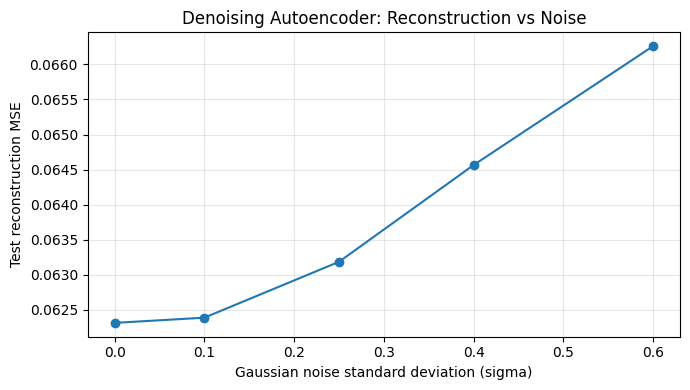

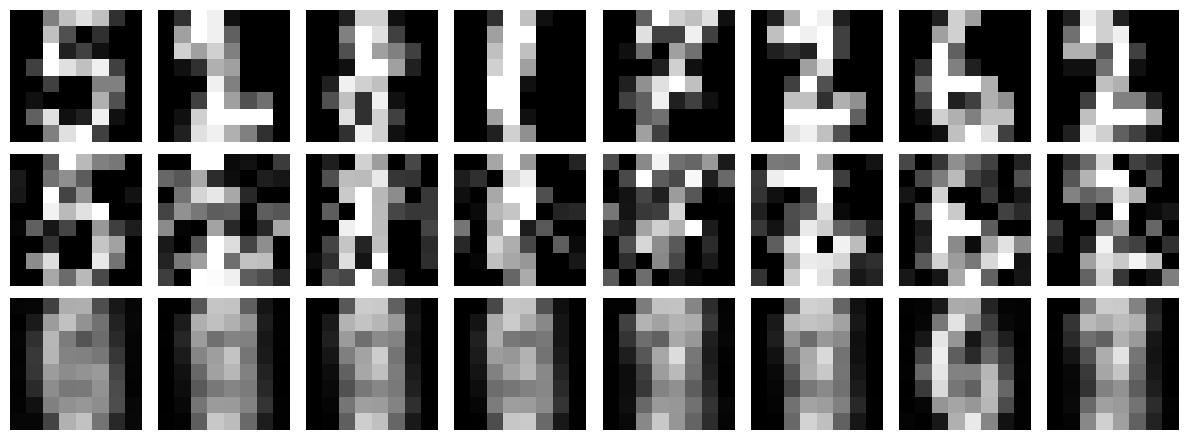

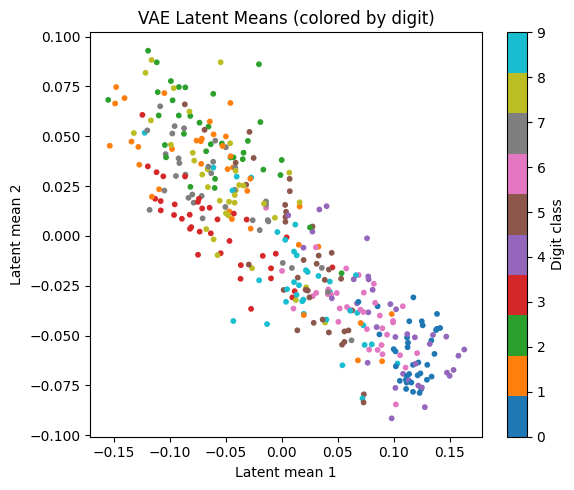

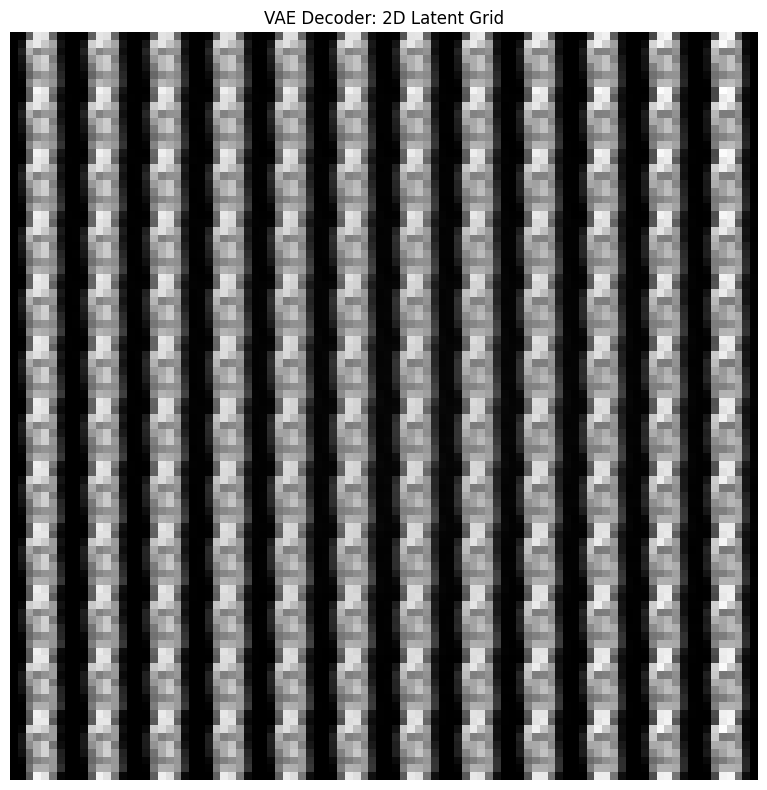

In [3]:
# Part 1 — Task 1.3: Stochastic Encoders and Decoders
# Implements BOTH required paradigms: Denoising Autoencoder (DAE) and VAE
# Dataset: sklearn Digits, normalized 8x8 images (64 features)

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)

digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
X_train, X_test, y_train, y_test = train_test_split(
    X, digits.target, test_size=0.2,
    random_state=42, stratify=digits.target
)

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train)),
    batch_size=128, shuffle=True
)
test_tensor = torch.tensor(X_test)

# ---------------------------------------------------------
# A. Denoising Autoencoder (DAE): corrupted input -> clean target
# ---------------------------------------------------------
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(2, 16), nn.ReLU(),
            nn.Linear(16, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

def add_noise(x, sigma):
    return torch.clamp(x + sigma * torch.randn_like(x), 0.0, 1.0)

dae = DenoisingAutoencoder()
mse = nn.MSELoss()
optimizer = torch.optim.Adam(dae.parameters(), lr=1e-3)
dae_epochs = 40
noise_sigma_train = 0.25
dae_history = []

for epoch in range(dae_epochs):
    dae.train()
    total = 0.0
    for (clean,) in train_loader:
        noisy = add_noise(clean, noise_sigma_train)
        optimizer.zero_grad()
        reconstruction = dae(noisy)
        loss = mse(reconstruction, clean)  # clean target is essential
        loss.backward()
        optimizer.step()
        total += loss.item() * clean.size(0)
    dae_history.append(total / len(X_train))

# Evaluate at several noise levels
noise_levels = [0.0, 0.1, 0.25, 0.4, 0.6]
dae_test_mse = {}
dae_examples = {}
dae.eval()
with torch.no_grad():
    for sigma in noise_levels:
        noisy = add_noise(test_tensor, sigma)
        reconstructed = dae(noisy)
        dae_test_mse[sigma] = mse(reconstructed, test_tensor).item()
        dae_examples[sigma] = (noisy.numpy(), reconstructed.numpy())

print("DAE test MSE by input noise level:")
for sigma, value in dae_test_mse.items():
    print(f"sigma={sigma:.2f}: MSE={value:.6f}")

# ---------------------------------------------------------
# B. Variational Autoencoder (VAE)
# ---------------------------------------------------------
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder_body = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU()
        )
        self.mu_layer = nn.Linear(16, latent_dim)
        self.logvar_layer = nn.Linear(16, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16), nn.ReLU(),
            nn.Linear(16, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder_body(x)
        return self.mu_layer(h), self.logvar_layer(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = VAE(latent_dim=2)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_epochs = 50
vae_history = []
beta_kl = 1.0

for epoch in range(vae_epochs):
    vae.train()
    total = 0.0
    for (x,) in train_loader:
        vae_optimizer.zero_grad()
        reconstruction, mu, logvar = vae(x)
        recon_loss = mse(reconstruction, x) * 64.0
        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        ) / x.size(0)
        loss = recon_loss + beta_kl * kl_loss
        loss.backward()
        vae_optimizer.step()
        total += loss.item() * x.size(0)
    vae_history.append(total / len(X_train))

vae.eval()
with torch.no_grad():
    vae_reconstruction, mu_test, logvar_test = vae(test_tensor)
    vae_test_mse = mse(vae_reconstruction, test_tensor).item()

print(f"VAE test reconstruction MSE: {vae_test_mse:.6f}")

# ---------------------------------------------------------
# C. Plot DAE noise sensitivity
# ---------------------------------------------------------
plt.figure(figsize=(7, 4))
plt.plot(noise_levels, [dae_test_mse[s] for s in noise_levels], marker="o")
plt.xlabel("Gaussian noise standard deviation (sigma)")
plt.ylabel("Test reconstruction MSE")
plt.title("Denoising Autoencoder: Reconstruction vs Noise")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show clean, noisy, and reconstructed examples at sigma=0.25
noisy, rec = dae_examples[0.25]
fig, axes = plt.subplots(3, 8, figsize=(12, 4.5))
for i in range(8):
    axes[0, i].imshow(X_test[i].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(noisy[i].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(rec[i].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    for row in range(3):
        axes[row, i].axis("off")
axes[0, 0].set_ylabel("Clean")
axes[1, 0].set_ylabel("Noisy")
axes[2, 0].set_ylabel("Denoised")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# D. Plot VAE latent means and decoder interpolation grid
# ---------------------------------------------------------
with torch.no_grad():
    mu_all, _ = vae.encode(test_tensor)
    mu_all = mu_all.numpy()

plt.figure(figsize=(6, 5))
plt.scatter(mu_all[:, 0], mu_all[:, 1], c=y_test, cmap="tab10", s=10)
plt.xlabel("Latent mean 1")
plt.ylabel("Latent mean 2")
plt.title("VAE Latent Means (colored by digit)")
plt.colorbar(label="Digit class")
plt.tight_layout()
plt.show()

grid_n = 12
grid_x = np.linspace(-2.5, 2.5, grid_n)
grid_y = np.linspace(-2.5, 2.5, grid_n)
canvas = np.zeros((grid_n * 8, grid_n * 8))
vae.eval()
with torch.no_grad():
    for row, yy in enumerate(grid_y):
        for col, xx in enumerate(grid_x):
            z = torch.tensor([[xx, yy]], dtype=torch.float32)
            image = vae.decode(z).numpy().reshape(8, 8)
            canvas[(grid_n - 1 - row) * 8:(grid_n - row) * 8,
                   col * 8:(col + 1) * 8] = image

plt.figure(figsize=(8, 8))
plt.imshow(canvas, cmap="gray")
plt.axis("off")
plt.title("VAE Decoder: 2D Latent Grid")
plt.tight_layout()
plt.show()


In [1]:
# Part 2 — Task 2.1: Restricted Boltzmann Machine (RBM)
# Dataset: sklearn Digits (64 normalized pixel features)
# Training: Contrastive Divergence CD-1
# Framework: PyTorch

import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

np.random.seed(42)
torch.manual_seed(42)

# Load the same dataset and preprocessing used in Part 1
digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

train_ds = TensorDataset(torch.tensor(X_train))
train_loader = DataLoader(
    train_ds,
    batch_size=128,
    shuffle=True
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (1437, 64)
Testing data shape: (360, 64)


In [3]:
class RBM:
    def __init__(self, n_visible=64, n_hidden=64, learning_rate=0.01):
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.learning_rate = learning_rate

        # Trainable parameters
        self.W = torch.randn(n_visible, n_hidden) * 0.01
        self.b = torch.zeros(n_visible)  # Visible bias
        self.c = torch.zeros(n_hidden)  # Hidden bias

    def sigmoid(self, x):
        return torch.sigmoid(x)

    # P(h_j = 1 | v)
    def hidden_prob(self, v):
        return self.sigmoid(v @ self.W + self.c)

    # P(v_i = 1 | h)
    def visible_prob(self, h):
        return self.sigmoid(h @ self.W.T + self.b)

    # Sample binary states from probabilities
    def sample(self, probabilities):
        return torch.bernoulli(probabilities)

    # Energy function E(v,h)
    def energy(self, v, h):
        interaction = torch.sum((v @ self.W) * h, dim=1)
        visible_bias = v @ self.b
        hidden_bias = h @ self.c

        return -(interaction + visible_bias + hidden_bias)

    # One-step Contrastive Divergence
    def cd1(self, v0):
        batch_size = v0.size(0)

        # Positive phase
        h0_prob = self.hidden_prob(v0)
        h0_sample = self.sample(h0_prob)

        # Negative phase: Gibbs sampling for one step
        v1_prob = self.visible_prob(h0_sample)
        v1_sample = self.sample(v1_prob)

        h1_prob = self.hidden_prob(v1_sample)

        # Manual parameter updates
        with torch.no_grad():
            positive_association = v0.T @ h0_prob
            negative_association = v1_sample.T @ h1_prob

            self.W += self.learning_rate * (
                positive_association - negative_association
            ) / batch_size

            self.b += self.learning_rate * torch.mean(
                v0 - v1_sample, dim=0
            )

            self.c += self.learning_rate * torch.mean(
                h0_prob - h1_prob, dim=0
            )

        return v1_prob

    def reconstruct(self, v):
        h_prob = self.hidden_prob(v)
        return self.visible_prob(h_prob)

In [4]:
# Initialize RBM
rbm = RBM(
    n_visible=64,
    n_hidden=64,
    learning_rate=0.01
)

epochs = 50
reconstruction_errors = []

for epoch in range(epochs):
    epoch_error = 0.0
    num_samples = 0

    for (v0,) in train_loader:
        # CD-1 update
        rbm.cd1(v0)

        # Reconstruction error
        with torch.no_grad():
            reconstructed = rbm.reconstruct(v0)
            error = torch.mean((v0 - reconstructed) ** 2)

        epoch_error += error.item() * v0.size(0)
        num_samples += v0.size(0)

    average_error = epoch_error / num_samples
    reconstruction_errors.append(average_error)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Reconstruction MSE: {average_error:.6f}"
        )

print("RBM training completed.")

Epoch [5/50], Reconstruction MSE: 0.076998
Epoch [10/50], Reconstruction MSE: 0.073806
Epoch [15/50], Reconstruction MSE: 0.073225
Epoch [20/50], Reconstruction MSE: 0.073000
Epoch [25/50], Reconstruction MSE: 0.072924
Epoch [30/50], Reconstruction MSE: 0.072882
Epoch [35/50], Reconstruction MSE: 0.072862
Epoch [40/50], Reconstruction MSE: 0.072834
Epoch [45/50], Reconstruction MSE: 0.072824
Epoch [50/50], Reconstruction MSE: 0.072805
RBM training completed.


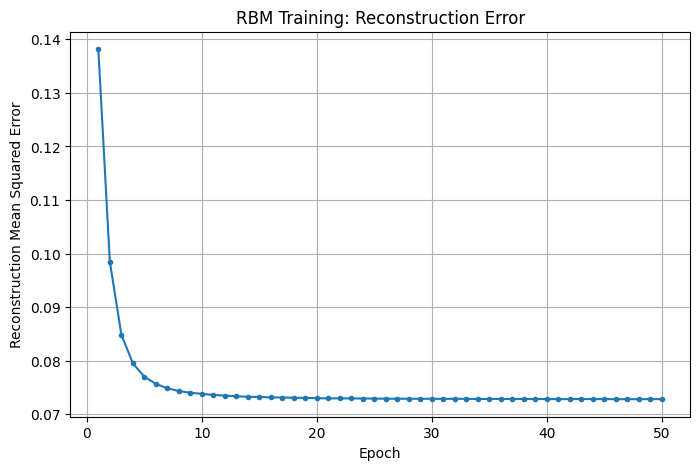

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, epochs + 1),
    reconstruction_errors,
    marker="o",
    markersize=3
)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Mean Squared Error")
plt.title("RBM Training: Reconstruction Error")
plt.grid(True)
plt.show()

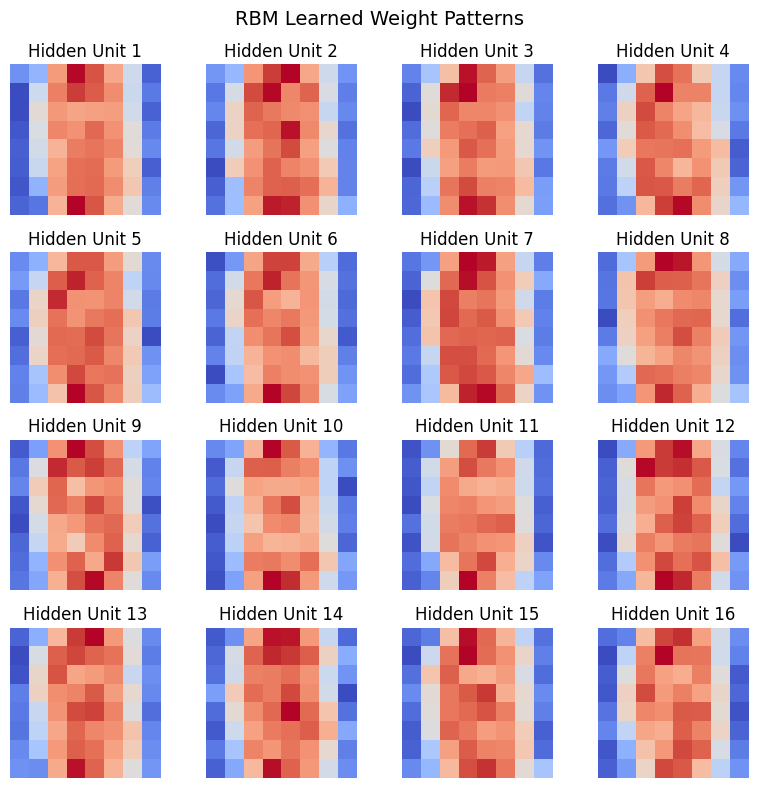

In [6]:
# Visualize the first 16 hidden-unit weight vectors
weights = rbm.W.detach().numpy().T

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    weight_image = weights[i].reshape(8, 8)

    im = ax.imshow(weight_image, cmap="coolwarm")
    ax.set_title(f"Hidden Unit {i + 1}")
    ax.axis("off")

plt.suptitle("RBM Learned Weight Patterns", fontsize=14)
plt.tight_layout()
plt.show()

Test Reconstruction MSE: 0.073893


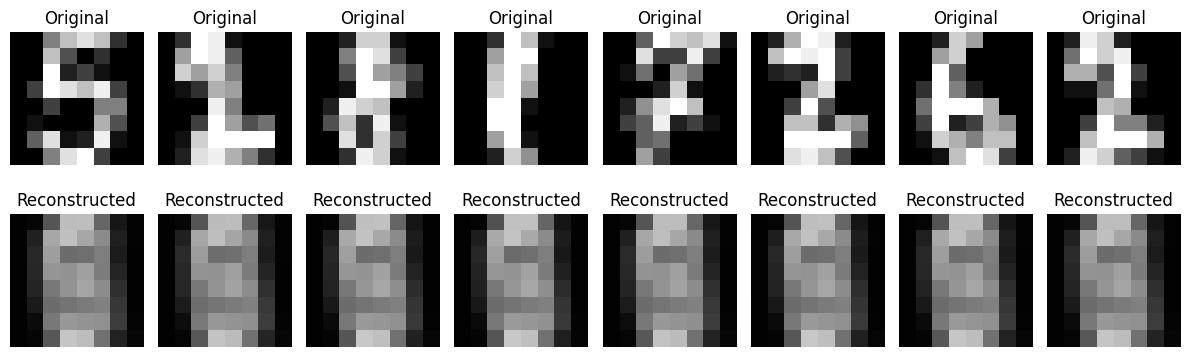

In [7]:
rbm.eval = True  # Evaluation marker; the RBM has no dropout or batch norm

X_test_tensor = torch.tensor(X_test)

with torch.no_grad():
    test_reconstructions = rbm.reconstruct(X_test_tensor)
    test_mse = torch.mean(
        (X_test_tensor - test_reconstructions) ** 2
    ).item()

print(f"Test Reconstruction MSE: {test_mse:.6f}")

# Display original and reconstructed digit images
fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    axes[0, i].imshow(
        X_test[i].reshape(8, 8),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        test_reconstructions[i].numpy().reshape(8, 8),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Task 2.2: DBN vs. Randomly Initialized Network

import copy
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
torch.manual_seed(42)

# Use only 10% of training samples as labeled data
X_labeled, _, y_labeled, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.10,
    random_state=42,
    stratify=y_train
)

X_labeled_tensor = torch.tensor(X_labeled, dtype=torch.float32)
y_labeled_tensor = torch.tensor(y_labeled, dtype=torch.long)

print("Labeled training samples:", len(X_labeled_tensor))
print("Test samples:", len(X_test))
print("Input features:", X_train.shape[1])

Labeled training samples: 143
Test samples: 360
Input features: 64


In [9]:
class LayerRBM:
    def __init__(self, n_visible, n_hidden, learning_rate=0.01):
        self.W = torch.randn(n_visible, n_hidden) * 0.01
        self.v_bias = torch.zeros(n_visible)
        self.h_bias = torch.zeros(n_hidden)
        self.lr = learning_rate

    def hidden_prob(self, v):
        return torch.sigmoid(v @ self.W + self.h_bias)

    def visible_prob(self, h):
        return torch.sigmoid(h @ self.W.T + self.v_bias)

    def train_batch(self, v0):
        batch_size = v0.shape[0]

        # Positive phase
        h0_prob = self.hidden_prob(v0)
        h0_sample = torch.bernoulli(h0_prob)

        # Negative phase: one Gibbs sampling step
        v1_prob = self.visible_prob(h0_sample)
        v1_sample = torch.bernoulli(v1_prob)
        h1_prob = self.hidden_prob(v1_sample)

        # Manual CD-1 parameter updates
        with torch.no_grad():
            self.W += self.lr * (
                (v0.T @ h0_prob) - (v1_sample.T @ h1_prob)
            ) / batch_size

            self.v_bias += self.lr * (v0 - v1_sample).mean(dim=0)
            self.h_bias += self.lr * (h0_prob - h1_prob).mean(dim=0)

    def transform(self, v):
        with torch.no_grad():
            return self.hidden_prob(v)

In [10]:
# Define the DBN architecture
layer_sizes = [64, 128, 64]
pretraining_epochs = 30
pretraining_batch_size = 128

# Input for the first RBM
layer_input = torch.tensor(X_train, dtype=torch.float32)

pretrained_rbms = []
pretraining_errors = []

for layer_index in range(len(layer_sizes) - 1):
    n_visible = layer_sizes[layer_index]
    n_hidden = layer_sizes[layer_index + 1]

    print(
        f"\nPretraining RBM layer {layer_index + 1}: "
        f"{n_visible} -> {n_hidden}"
    )

    rbm_layer = LayerRBM(
        n_visible=n_visible,
        n_hidden=n_hidden,
        learning_rate=0.01
    )

    layer_dataset = TensorDataset(layer_input)
    layer_loader = DataLoader(
        layer_dataset,
        batch_size=pretraining_batch_size,
        shuffle=True
    )

    layer_errors = []

    for epoch in range(pretraining_epochs):
        total_error = 0.0
        total_samples = 0

        for (batch,) in layer_loader:
            rbm_layer.train_batch(batch)

            with torch.no_grad():
                hidden = torch.bernoulli(rbm_layer.hidden_prob(batch))
                reconstruction = rbm_layer.visible_prob(hidden)
                batch_error = ((batch - reconstruction) ** 2).mean()

            total_error += batch_error.item() * len(batch)
            total_samples += len(batch)

        mean_error = total_error / total_samples
        layer_errors.append(mean_error)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{pretraining_epochs}, "
                f"Reconstruction MSE: {mean_error:.5f}"
            )

    pretrained_rbms.append(rbm_layer)
    pretraining_errors.append(layer_errors)

    # Transform data for the next layer
    layer_input = rbm_layer.transform(layer_input)

print("\nLayer-wise pretraining completed.")


Pretraining RBM layer 1: 64 -> 128
Epoch 10/30, Reconstruction MSE: 0.07339
Epoch 20/30, Reconstruction MSE: 0.07319
Epoch 30/30, Reconstruction MSE: 0.07310

Pretraining RBM layer 2: 128 -> 64
Epoch 10/30, Reconstruction MSE: 0.00028
Epoch 20/30, Reconstruction MSE: 0.00027
Epoch 30/30, Reconstruction MSE: 0.00025

Layer-wise pretraining completed.


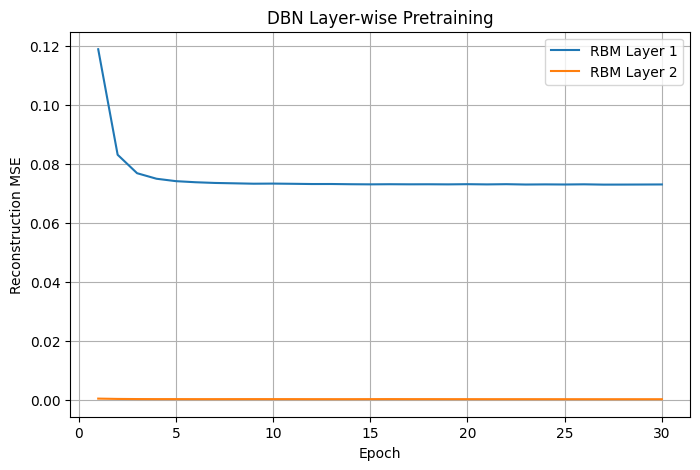

In [11]:
plt.figure(figsize=(8, 5))

for i, errors in enumerate(pretraining_errors):
    plt.plot(
        range(1, len(errors) + 1),
        errors,
        label=f"RBM Layer {i + 1}"
    )

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("DBN Layer-wise Pretraining")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
class DBNClassifier(nn.Module):
    def __init__(self, rbm_layers=None):
        super().__init__()

        self.fc1 = nn.Linear(64, 128)
        self.fc2 = nn.Linear(128, 64)
        self.classifier = nn.Linear(64, 10)

        # Initialize the first two layers from pretrained RBMs
        if rbm_layers is not None:
            with torch.no_grad():
                self.fc1.weight.copy_(rbm_layers[0].W.T)
                self.fc1.bias.copy_(rbm_layers[0].h_bias)

                self.fc2.weight.copy_(rbm_layers[1].W.T)
                self.fc2.bias.copy_(rbm_layers[1].h_bias)

    def forward(self, x):
        x = torch.sigmoid(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        return self.classifier(x)


# DBN pretrained model
dbn_model = DBNClassifier(pretrained_rbms)

# Identical architecture with random initialization
random_model = DBNClassifier()

In [14]:
def train_classifier(model, X_train_tensor, y_train_tensor,
                     X_test_array, y_test_array,
                     epochs=100, learning_rate=0.001):

    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()

    dataset = TensorDataset(X_train_tensor, y_train_tensor)
    loader = DataLoader(dataset, batch_size=32, shuffle=True)

    test_x = torch.tensor(X_test_array, dtype=torch.float32)
    test_y = torch.tensor(y_test_array, dtype=torch.long)

    loss_history = []
    accuracy_history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for xb, yb in loader:
            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(xb)

        loss_history.append(total_loss / len(dataset))

        model.eval()
        with torch.no_grad():
            predictions = model(test_x).argmax(dim=1)
            accuracy = (predictions == test_y).float().mean().item()

        accuracy_history.append(accuracy)

        if (epoch + 1) % 20 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs}, "
                f"Loss: {loss_history[-1]:.4f}, "
                f"Test Accuracy: {accuracy:.4f}"
            )

    return loss_history, accuracy_history


print("Training DBN-pretrained classifier...")
dbn_loss, dbn_accuracy = train_classifier(
    dbn_model,
    X_labeled_tensor,
    y_labeled_tensor,
    X_test,
    y_test,
    epochs=100
)

print("\nTraining randomly initialized classifier...")
random_loss, random_accuracy = train_classifier(
    random_model,
    X_labeled_tensor,
    y_labeled_tensor,
    X_test,
    y_test,
    epochs=100
)

Training DBN-pretrained classifier...
Epoch 20/100, Loss: 2.2779, Test Accuracy: 0.1750
Epoch 40/100, Loss: 1.9538, Test Accuracy: 0.5167
Epoch 60/100, Loss: 1.2826, Test Accuracy: 0.6694
Epoch 80/100, Loss: 0.8771, Test Accuracy: 0.7694
Epoch 100/100, Loss: 0.6403, Test Accuracy: 0.7944

Training randomly initialized classifier...
Epoch 20/100, Loss: 2.2380, Test Accuracy: 0.4306
Epoch 40/100, Loss: 1.8907, Test Accuracy: 0.6194
Epoch 60/100, Loss: 1.2234, Test Accuracy: 0.7389
Epoch 80/100, Loss: 0.8258, Test Accuracy: 0.7889
Epoch 100/100, Loss: 0.5985, Test Accuracy: 0.8139


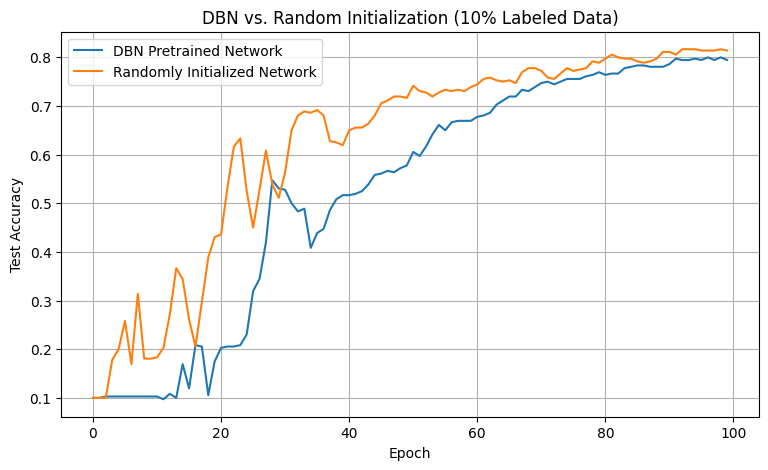

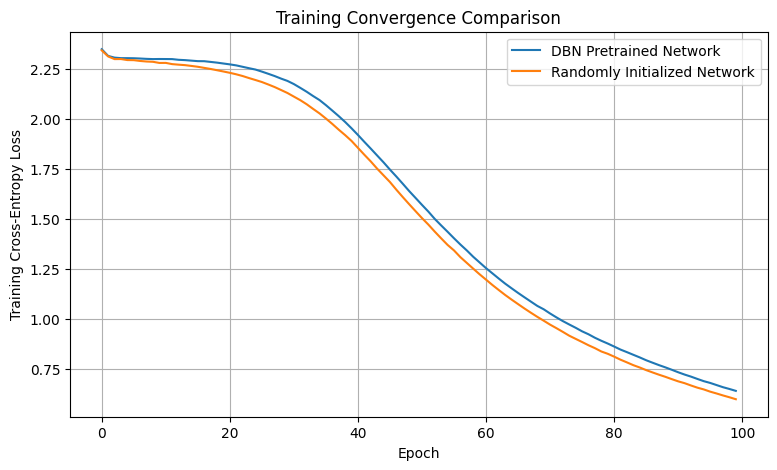

In [15]:
# Plot test accuracy across epochs
plt.figure(figsize=(9, 5))

plt.plot(dbn_accuracy, label="DBN Pretrained Network")
plt.plot(random_accuracy, label="Randomly Initialized Network")

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("DBN vs. Random Initialization (10% Labeled Data)")
plt.legend()
plt.grid(True)
plt.show()


# Plot training loss
plt.figure(figsize=(9, 5))

plt.plot(dbn_loss, label="DBN Pretrained Network")
plt.plot(random_loss, label="Randomly Initialized Network")

plt.xlabel("Epoch")
plt.ylabel("Training Cross-Entropy Loss")
plt.title("Training Convergence Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
from sklearn.metrics import accuracy_score, classification_report

dbn_model.eval()
random_model.eval()

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

with torch.no_grad():
    dbn_predictions = dbn_model(X_test_tensor).argmax(dim=1).numpy()
    random_predictions = random_model(X_test_tensor).argmax(dim=1).numpy()

dbn_final_accuracy = accuracy_score(y_test, dbn_predictions)
random_final_accuracy = accuracy_score(y_test, random_predictions)

print("=" * 60)
print("FINAL COMPARISON: DBN vs RANDOM NETWORK")
print("=" * 60)

print(f"DBN Pretrained Network Accuracy: {dbn_final_accuracy:.4f}")
print(f"Random Network Accuracy:        {random_final_accuracy:.4f}")

print("\nComparative Table")
print("-" * 60)
print(f"{'Model':<35}{'Test Accuracy':>15}")
print("-" * 60)
print(f"{'DBN Pretrained Network':<35}{dbn_final_accuracy:>15.4f}")
print(f"{'Randomly Initialized Network':<35}{random_final_accuracy:>15.4f}")
print("-" * 60)

print("\nDBN Classification Report:")
print(classification_report(y_test, dbn_predictions, zero_division=0))

FINAL COMPARISON: DBN vs RANDOM NETWORK
DBN Pretrained Network Accuracy: 0.7944
Random Network Accuracy:        0.8139

Comparative Table
------------------------------------------------------------
Model                                Test Accuracy
------------------------------------------------------------
DBN Pretrained Network                      0.7944
Randomly Initialized Network                0.8139
------------------------------------------------------------

DBN Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.92      0.94        36
           1       0.71      0.75      0.73        36
           2       0.76      0.74      0.75        35
           3       0.72      0.89      0.80        37
           4       0.85      0.97      0.91        36
           5       0.80      0.86      0.83        37
           6       0.88      0.97      0.92        36
           7       0.82      0.89      0.85        36
           

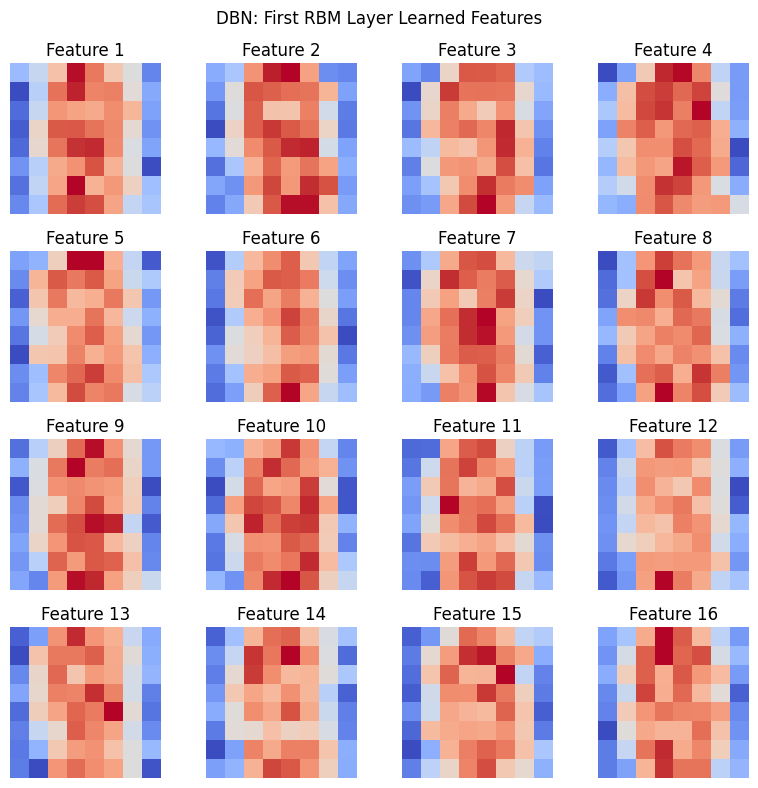

In [17]:
first_layer_weights = pretrained_rbms[0].W.detach().numpy().T

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(first_layer_weights[i].reshape(8, 8), cmap="coolwarm")
    ax.set_title(f"Feature {i + 1}")
    ax.axis("off")

plt.suptitle("DBN: First RBM Layer Learned Features")
plt.tight_layout()
plt.show()